#### Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path
from scipy.sparse import load_npz

from sklearn.linear_model import RidgeClassifier
from sklearn.utils.validation import check_is_fitted

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", "{:.4f}".format)

# Visualization settings
sns.set_theme(style="whitegrid")

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


#### Loading the Processed Datasets and Identifying Feature Artifacts

In [2]:
# Defining project directories
processed_dir = Path("../data/processed")
features_dir = processed_dir / "features"
models_dir = Path("../models")

# Loading processed datasets
train_df = pd.read_csv(processed_dir / "train.csv")
test_df = pd.read_csv(processed_dir / "test.csv")

# Loading encoded target variables
y_train = np.load(features_dir / "y_train.npy")
y_test = np.load(features_dir / "y_test.npy")

# Displaying dataset dimensions
print("Dataset Dimensions:")
print(f"Training Dataset: {train_df.shape}")
print(f"Test Dataset: {test_df.shape}")
print(f"Training Target: {y_train.shape}")
print(f"Test Target: {y_test.shape}")

# Identifying available feature artifacts
print("\nAvailable Feature Matrices:")
for file in sorted(features_dir.glob("*.npz")):
    print(f" - {file.name}")

# Identifying saved preprocessing artifacts
print("\nAvailable Preprocessing Artifacts:")
for file in sorted(models_dir.iterdir()):
    if file.is_file():
        print(f" - {file.name}")

# Validating target alignment
assert len(train_df) == len(y_train)
assert len(test_df) == len(y_test)

print("\nDatasets loaded and validated successfully.")

Dataset Dimensions:
Training Dataset: (28919, 8)
Test Dataset: (6391, 8)
Training Target: (28919,)
Test Target: (6391,)

Available Feature Matrices:
 - X_test_char.npz
 - X_test_combined.npz
 - X_test_word.npz
 - X_train_char.npz
 - X_train_combined.npz
 - X_train_word.npz

Available Preprocessing Artifacts:
 - char_tfidf_vectorizer.joblib
 - label_encoder.joblib
 - word_tfidf_vectorizer.joblib

Datasets loaded and validated successfully.


#### Loading Character TF-IDF Features and Preprocessing Artifacts

In [3]:
# Loading character-level TF-IDF feature matrices
X_train_char = load_npz(features_dir / "X_train_char.npz")
X_test_char = load_npz(features_dir / "X_test_char.npz")

# Loading fitted preprocessing artifacts
char_vectorizer = joblib.load(
    models_dir / "char_tfidf_vectorizer.joblib"
)

label_encoder = joblib.load(
    models_dir / "label_encoder.joblib"
)

# Extracting feature names and product categories
feature_names = char_vectorizer.get_feature_names_out()
category_names = label_encoder.classes_

# Displaying feature information
print("Character TF-IDF Feature Matrices:")
print(f"Training Features: {X_train_char.shape}")
print(f"Test Features: {X_test_char.shape}")

print("\nFeature Information:")
print(f"Total Character Features: {len(feature_names):,}")
print(f"Total Product Categories: {len(category_names)}")

print("\nProduct Categories:")
for idx, category in enumerate(category_names):
    print(f"{idx}: {category}")

# Validating feature consistency
assert X_train_char.shape[0] == len(y_train)
assert X_test_char.shape[0] == len(y_test)

assert X_train_char.shape[1] == len(feature_names)
assert X_test_char.shape[1] == len(feature_names)

assert len(category_names) == len(np.unique(y_train))

print("\nFeature matrices and preprocessing artifacts validated successfully.")

Character TF-IDF Feature Matrices:
Training Features: (28919, 50000)
Test Features: (6391, 50000)

Feature Information:
Total Character Features: 50,000
Total Product Categories: 10

Product Categories:
0: CPUs
1: Digital Cameras
2: Dishwashers
3: Freezers
4: Fridge Freezers
5: Fridges
6: Microwaves
7: Mobile Phones
8: TVs
9: Washing Machines

Feature matrices and preprocessing artifacts validated successfully.


#### Reconstructing the Tuned Ridge Classifier

In [4]:
# Initializing the selected Ridge Classifier
final_model = RidgeClassifier(
    alpha=0.5
)

# Fitting the model on the training features
final_model.fit(X_train_char, y_train)

# Validating the fitted model
check_is_fitted(final_model)

# Extracting model coefficients
model_coefficients = final_model.coef_

# Displaying model information
print("Selected Model: Ridge Classifier")
print(f"Regularization Strength (Alpha): {final_model.alpha}")

print("\nModel Coefficient Information:")
print(f"Coefficient Matrix Shape: {model_coefficients.shape}")
print(f"Number of Classes: {len(final_model.classes_)}")
print(f"Number of Features: {model_coefficients.shape[1]:,}")

# Validating coefficient dimensions
assert model_coefficients.shape == (
    len(category_names),
    len(feature_names)
)

assert np.array_equal(
    final_model.classes_,
    np.arange(len(category_names))
)

print("\nTuned Ridge Classifier reconstructed successfully.")

Selected Model: Ridge Classifier
Regularization Strength (Alpha): 0.5

Model Coefficient Information:
Coefficient Matrix Shape: (10, 50000)
Number of Classes: 10
Number of Features: 50,000

Tuned Ridge Classifier reconstructed successfully.


#### Identifying the Most Influential Character Features

In [5]:
# Defining the number of features to examine
top_n = 10

# Extracting top positive coefficients for each category
top_features_records = []

for class_idx, category in enumerate(category_names):

    # Retrieving category-specific coefficients
    coefficients = model_coefficients[class_idx]

    # Identifying the strongest positive coefficients
    top_indices = np.argsort(coefficients)[-top_n:][::-1]

    for rank, feature_idx in enumerate(top_indices, start=1):

        top_features_records.append({
            "Category": category,
            "Rank": rank,
            "Character_Feature": feature_names[feature_idx],
            "Coefficient": coefficients[feature_idx]
        })

# Creating the feature importance table
top_features_df = pd.DataFrame(top_features_records)

print("Top 10 Positive Character Features by Product Category:")

display(
    top_features_df.pivot(
        index="Rank",
        columns="Category",
        values="Character_Feature"
    )
)

print("\nCategory-wise feature importance extracted successfully.")

Top 10 Positive Character Features by Product Category:


Category,CPUs,Digital Cameras,Dishwashers,Freezers,Fridge Freezers,Fridges,Microwaves,Mobile Phones,TVs,Washing Machines
Rank,,,,,,,,,,
1,ghz,mm,dw,fr,kg,fr,m/r,fon,tv,wm
2,mb,dsc,di,fn,rf,k,nn,ia,tv,wa
3,hz,dsc,g/s,gn,cn,ik,mw,bv,tv,ww
4,ghz,fz,mdi,ig,nr,ks,mwh,cat,2/,wd
5,amd,j1,mdi,rz,ka,rl,bm,e1,ue,wm1
6,amd,tz,sn,gs,ic,zba,hmt,p6,tx,r/l
7,amd,dc,dis,gp,rcb,zba,m54,oro,kd,/wd
8,amd,pix,adp,gi,rb3,ki,nn,lg,49,was
9,md,lei,zd,zf,ct,kb,9002,hon,led,w/w



Category-wise feature importance extracted successfully.


**Observations on Influential Character Features:**

- **CPUs** are strongly associated with technical patterns such as `ghz`, `amd`, and `mb`, while **Digital Cameras** exhibit features such as `dsc` and `pix`.
- **TVs** show recognizable patterns such as `tv` and `led`, while **Washing Machines** contain sequences such as `wm`, `wa`, and `was`.
- Several categories rely on short character fragments and model identifiers, indicating that the classifier learns both recognizable product terminology and category-specific naming conventions.

#### Visualizing Category-Specific Character Feature Importance

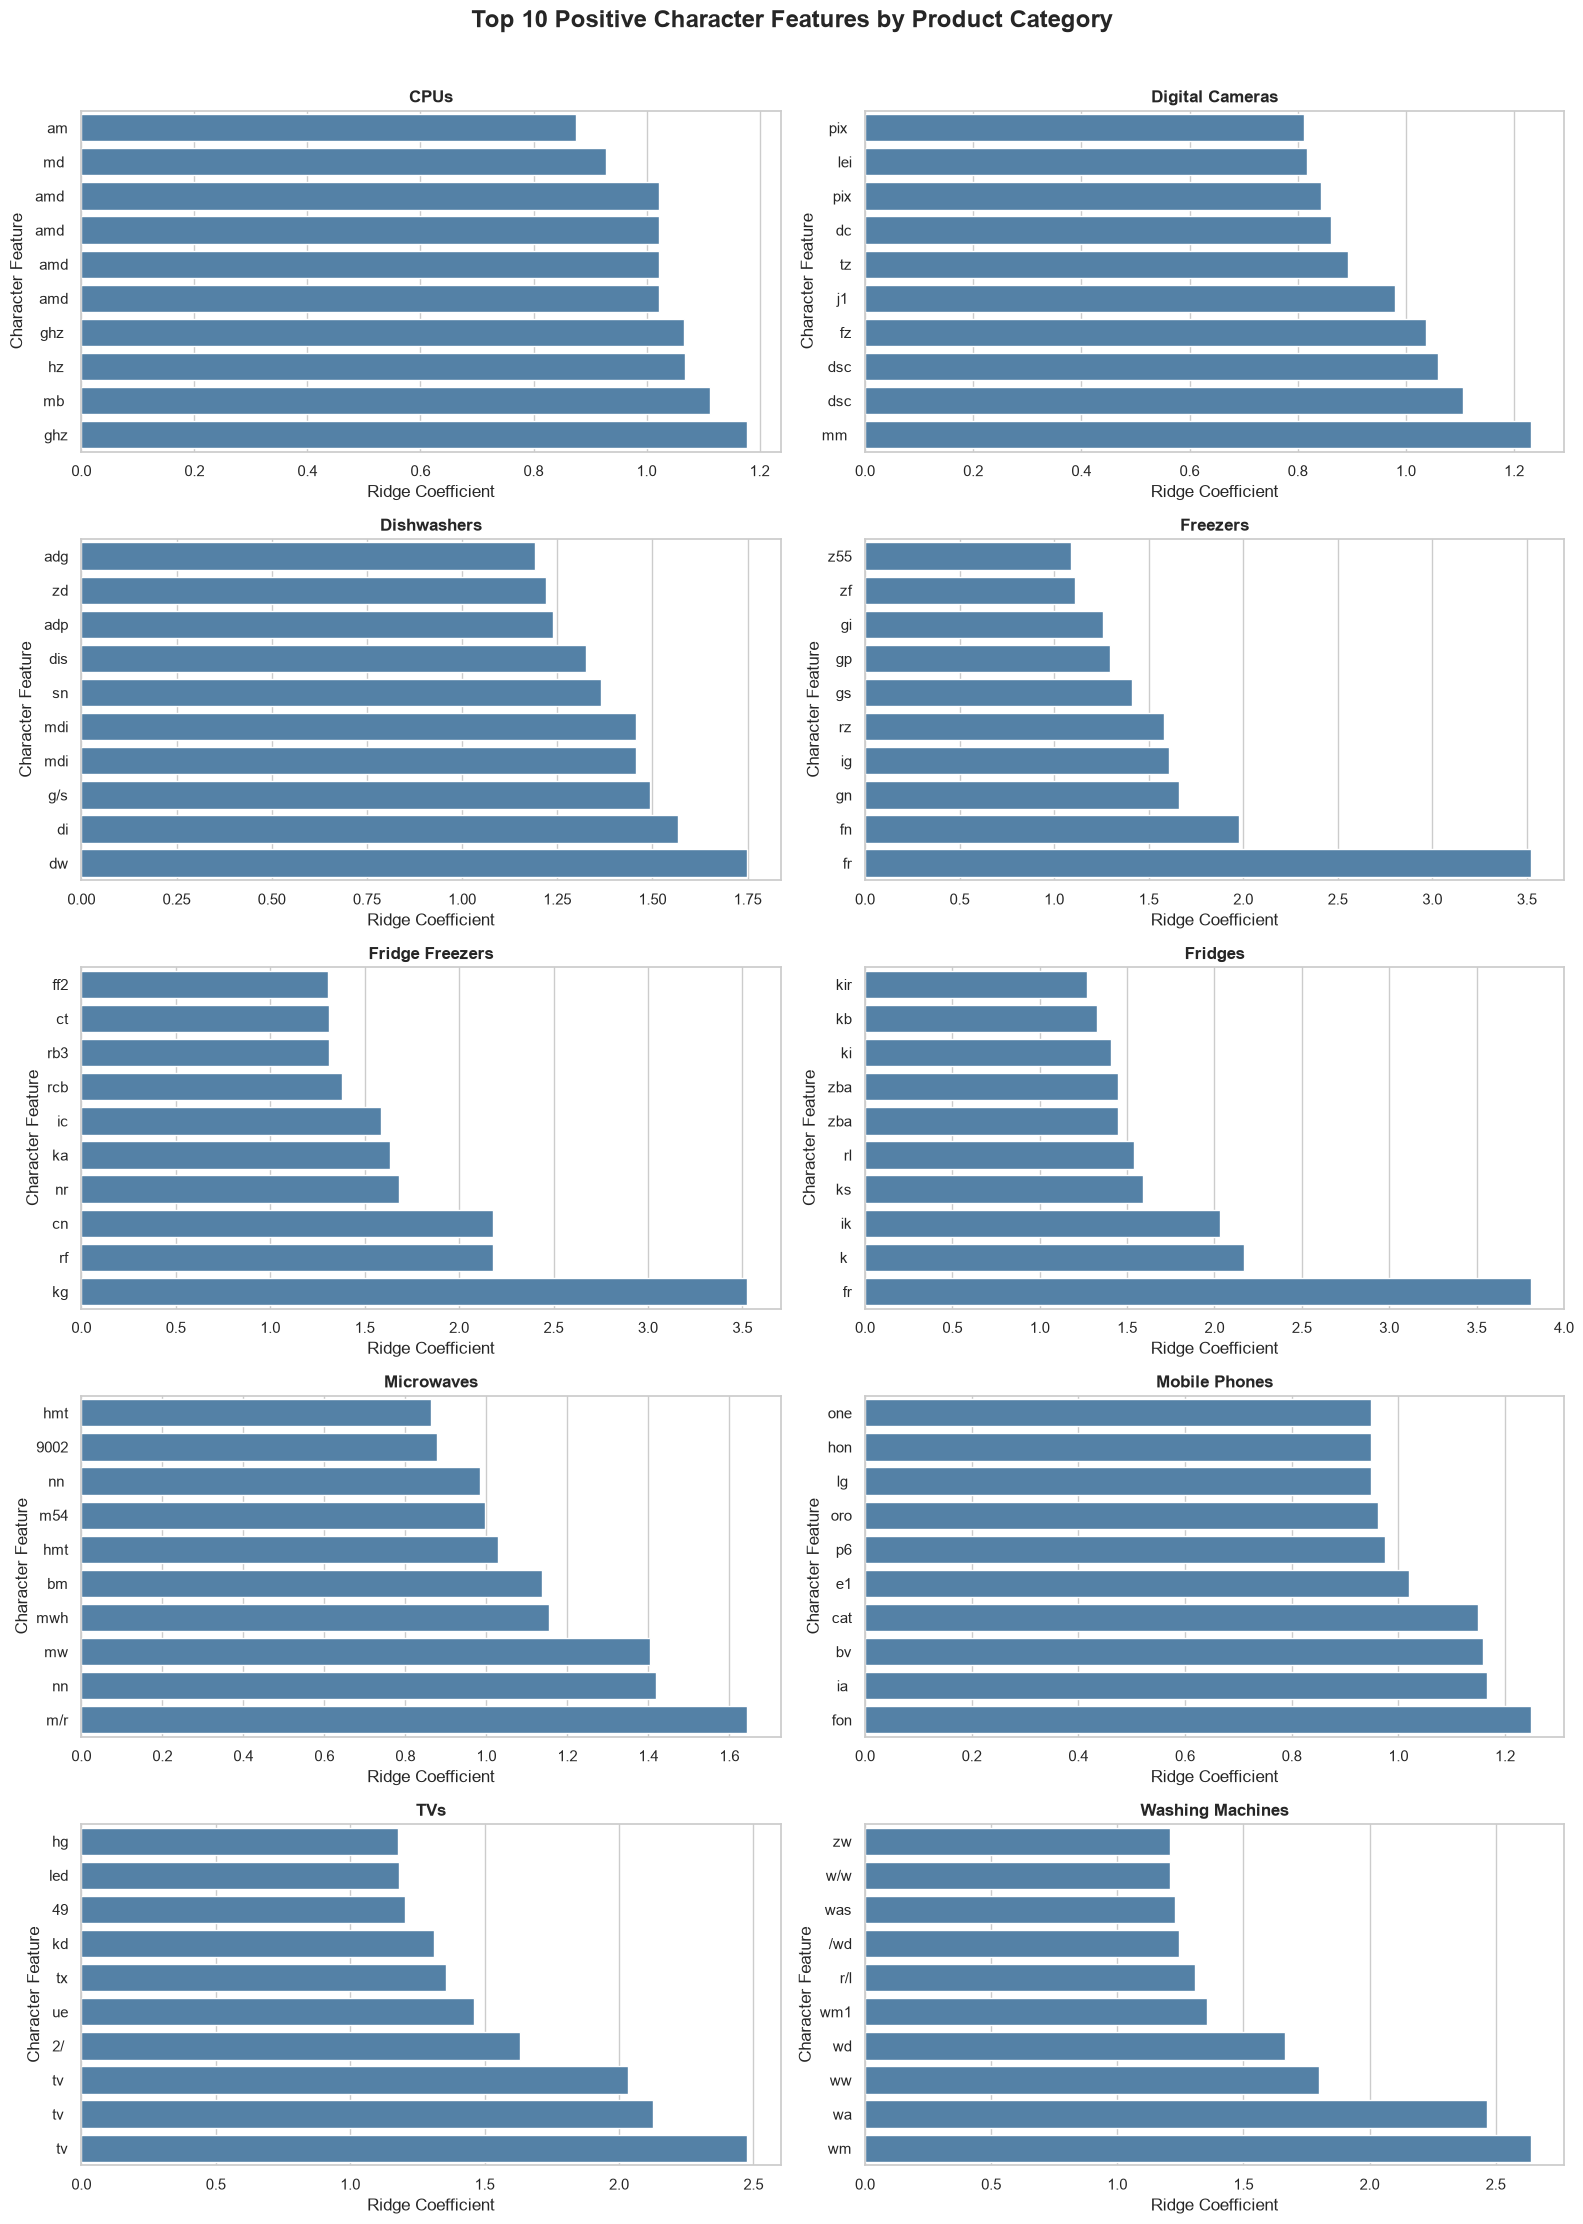

In [6]:
# Creating category-wise coefficient visualizations
fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(16, 22)
)

axes = axes.flatten()

for idx, category in enumerate(category_names):

    # Selecting the top features for the category
    category_features = (
        top_features_df[
            top_features_df["Category"] == category
        ]
        .sort_values("Coefficient", ascending=True)
    )

    # Plotting positive coefficients
    sns.barplot(
        data=category_features,
        x="Coefficient",
        y="Character_Feature",
        color="steelblue",
        ax=axes[idx]
    )

    axes[idx].set_title(
        category,
        fontsize=12,
        fontweight="bold"
    )

    axes[idx].set_xlabel("Ridge Coefficient")
    axes[idx].set_ylabel("Character Feature")

plt.suptitle(
    "Top 10 Positive Character Features by Product Category",
    fontsize=17,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

#### Identifying the Most Influential Negative Character Features

In [7]:
# Defining the number of negative features to examine
top_n_negative = 10

# Extracting the strongest negative coefficients
negative_features_records = []

for class_idx, category in enumerate(category_names):

    # Retrieving category-specific coefficients
    coefficients = model_coefficients[class_idx]

    # Identifying the most negative coefficients
    bottom_indices = np.argsort(coefficients)[:top_n_negative]

    for rank, feature_idx in enumerate(bottom_indices, start=1):

        negative_features_records.append({
            "Category": category,
            "Rank": rank,
            "Character_Feature": feature_names[feature_idx],
            "Coefficient": coefficients[feature_idx]
        })

# Creating the negative feature importance table
negative_features_df = pd.DataFrame(
    negative_features_records
)

print("Top 10 Negative Character Features by Product Category:")

display(
    negative_features_df.pivot(
        index="Rank",
        columns="Category",
        values="Character_Feature"
    )
)

print("\nNegative character feature importance extracted successfully.")

Top 10 Negative Character Features by Product Category:


Category,CPUs,Digital Cameras,Dishwashers,Freezers,Fridge Freezers,Fridges,Microwaves,Mobile Phones,TVs,Washing Machines
Rank,,,,,,,,,,
1,bl21,ektr,wa,idge,fr,kg,fr,tv,oled,ing
2,lg,ktr,wash,dge,der,cn,rs1,tv,mp,ing
3,lg,nn,wm,frid,fn,ezer,drs1,tv,5.,ng
4,1500,kd,kg,fri,gn,freez,drs1,rs,visi,dish
5,bl21,tx,was,frid,kb,zer,drs,f14,gs,ish
6,bl21,nn,disp,fridg,fab2,ezer,drs,cf,vis,dish
7,960,ek,disp,ge,fab28,eezer,4j,ue,ca,ishw
8,40v,ekt,isp,fri,fab2,eze,ki,f4j,s5,dishw
9,9c,tv,68i,cn,ab340,zer,k,fr,nn,hwash



Negative character feature importance extracted successfully.


**Observations on Negative Character Feature Importance:**

- **Dishwashers** exhibit strongly negative coefficients for washing-machine-related patterns such as `wash`, `wm`, and `was`, indicating that these features reduce the Dishwasher decision score.
- **Fridges** show negative coefficients for `freez`, `ezer`, and `zer`, while **Freezers** show negative coefficients for `frid` and `fridge` fragments, highlighting how the model distinguishes related refrigeration categories.
- **Mobile Phones** exhibit negative coefficients for `tv`, while **Washing Machines** show negative coefficients for `dish` and `dishw`, demonstrating the role of category-specific terminology in separating competing product classes.

#### Analyzing Global Character Feature Importance

In [8]:
# Calculating global feature importance
global_importance = np.max(
    np.abs(model_coefficients),
    axis=0
)

# Identifying the top 20 globally influential features
top_global_indices = np.argsort(
    global_importance
)[-20:][::-1]

# Creating the global importance summary
global_features_df = pd.DataFrame({
    "Character_Feature": feature_names[top_global_indices],
    "Global_Importance": global_importance[top_global_indices],
    "Most_Influenced_Category": category_names[
        np.argmax(
            np.abs(model_coefficients[:, top_global_indices]),
            axis=0
        )
    ]
})

print("Top 20 Globally Influential Character Features:")

display(
    global_features_df.round(4)
)

print("\nGlobal character feature importance analysis completed successfully.")

Top 20 Globally Influential Character Features:


,Character_Feature,Global_Importance,Most_Influenced_Category
0,fr,5.4142,Fridge Freezers
1,kg,3.5263,Fridge Freezers
2,wm,2.6398,Washing Machines
3,tv,2.4773,TVs
4,wa,2.4644,Washing Machines
5,rf,2.1821,Fridge Freezers
6,cn,2.1788,Fridge Freezers
7,k,2.1696,Fridges
8,tv,2.1249,TVs
9,tv,2.0322,TVs



Global character feature importance analysis completed successfully.


**Observations on Global Character Feature Importance:**

- Refrigeration-related categories contain several of the strongest coefficients, including `fr` (**5.4142**) and `kg` (**3.5263**), both associated with Fridge Freezers.
- Recognizable patterns such as `wm`, `tv`, and `dw` demonstrate that the classifier learns character sequences associated with specific product categories.
- Several highly ranked features are short character fragments or model-related sequences, indicating that predictions rely on both recognizable terminology and product naming conventions.

#### Visualizing Global Character Feature Importance

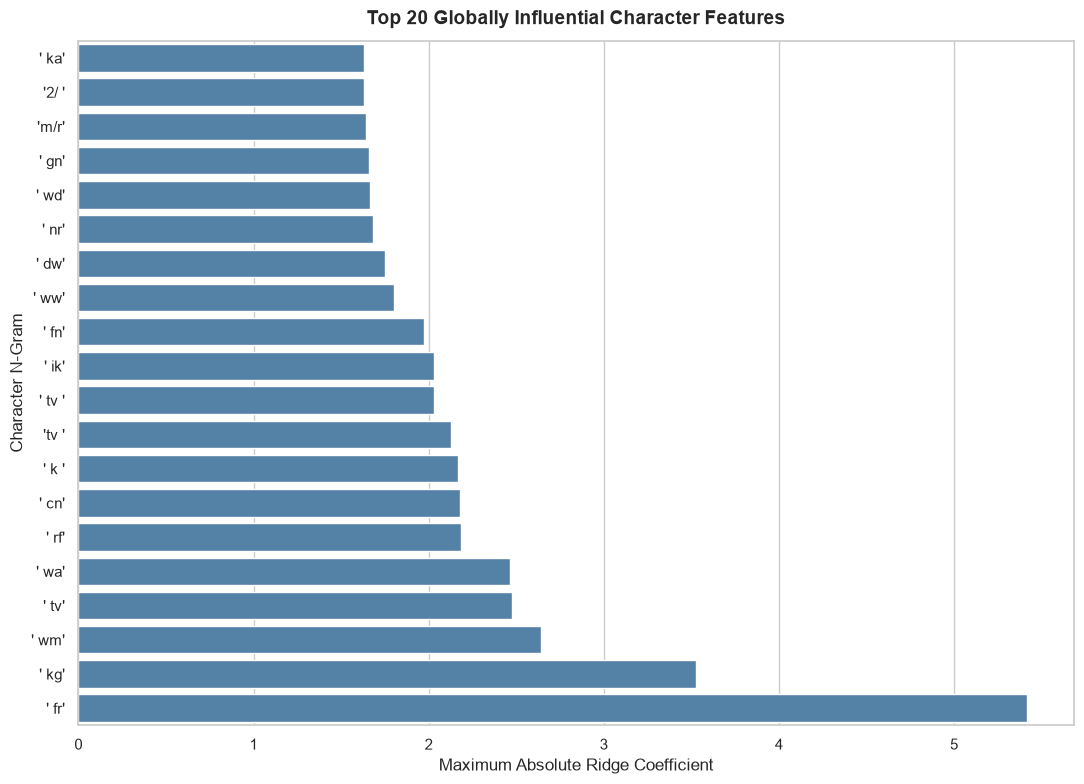

In [9]:
# Preparing global feature importance data
global_plot_df = global_features_df.copy()

# Making whitespace visible in character n-grams
global_plot_df["Feature_Label"] = (
    global_plot_df["Character_Feature"]
    .apply(lambda x: repr(x))
)

# Sorting features by global importance
global_plot_df = global_plot_df.sort_values(
    "Global_Importance",
    ascending=True
)

# Creating the visualization
fig, ax = plt.subplots(figsize=(11, 8))

sns.barplot(
    data=global_plot_df,
    x="Global_Importance",
    y="Feature_Label",
    color="steelblue",
    ax=ax
)

ax.set_title(
    "Top 20 Globally Influential Character Features",
    fontsize=14,
    fontweight="bold",
    pad=12
)

ax.set_xlabel("Maximum Absolute Ridge Coefficient")
ax.set_ylabel("Character N-Gram")

plt.tight_layout()
plt.show()

#### Identifying Representative Product Predictions

In [10]:
# Generating predictions on the test dataset
y_test_pred = final_model.predict(X_test_char)

# Identifying correct and incorrect predictions
correct_indices = np.flatnonzero(y_test == y_test_pred)
incorrect_indices = np.flatnonzero(y_test != y_test_pred)

# Selecting representative samples
correct_sample_idx = int(correct_indices[0])
incorrect_sample_idx = int(incorrect_indices[0])

# Creating the sample summary
representative_samples_df = pd.DataFrame({
    "Sample_Type": ["Correct Prediction", "Incorrect Prediction"],
    "Test_Index": [correct_sample_idx, incorrect_sample_idx],
    "Product_Title": [
        test_df.iloc[correct_sample_idx]["Product_Title"],
        test_df.iloc[incorrect_sample_idx]["Product_Title"]
    ],
    "Actual_Category": label_encoder.inverse_transform([
        y_test[correct_sample_idx],
        y_test[incorrect_sample_idx]
    ]),
    "Predicted_Category": label_encoder.inverse_transform([
        y_test_pred[correct_sample_idx],
        y_test_pred[incorrect_sample_idx]
    ])
})

print("Representative Product Predictions:")
display(representative_samples_df)

print("\nRepresentative samples identified successfully.")

Representative Product Predictions:


,Sample_Type,Test_Index,Product_Title,Actual_Category,Predicted_Category
0,Correct Prediction,0,iphone 6s space grey 128gb 4.7 unlocked sim free,Mobile Phones,Mobile Phones
1,Incorrect Prediction,230,android 4.4.4 802.11 a/b/g/n 1d/2d imager hi2d 1.2 ghz quad core,Mobile Phones,CPUs



Representative samples identified successfully.


**Observations on Representative Product Predictions:**

- The correctly classified iPhone title contains recognizable mobile-phone terminology, including `iphone`, `128gb`, and `sim free`.
- The incorrectly classified Android device title contains processor-related specifications such as `1.2 ghz` and `quad core`, which may create ambiguity between Mobile Phones and CPUs.
- These examples provide an opportunity to examine how individual character features influence correct and incorrect category predictions.

#### Analyzing Local Feature Contributions for Individual Predictions

In [11]:
# Defining representative test samples
sample_indices = {
    "Correct Prediction": correct_sample_idx,
    "Incorrect Prediction": incorrect_sample_idx
}

# Extracting local feature contributions
local_contribution_records = []

for sample_type, sample_idx in sample_indices.items():

    # Retrieving the predicted category
    predicted_class = int(y_test_pred[sample_idx])

    # Extracting active TF-IDF features
    sample_features = X_test_char.getrow(sample_idx)

    active_indices = sample_features.indices
    active_values = sample_features.data

    # Calculating contributions to the predicted category score
    contributions = (
        active_values
        * model_coefficients[predicted_class, active_indices]
    )

    # Identifying the strongest positive contributions
    top_indices = np.argsort(contributions)[-10:][::-1]

    for rank, position in enumerate(top_indices, start=1):

        local_contribution_records.append({
            "Sample_Type": sample_type,
            "Predicted_Category": category_names[predicted_class],
            "Rank": rank,
            "Character_Feature": repr(
                feature_names[active_indices[position]]
            ),
            "TFIDF_Value": active_values[position],
            "Coefficient": model_coefficients[
                predicted_class, active_indices[position]
            ],
            "Contribution": contributions[position]
        })

# Creating the local contribution table
local_contributions_df = pd.DataFrame(
    local_contribution_records
)

print("Top 10 Positive Feature Contributions by Prediction:")

for sample_type in sample_indices:

    print(f"\n{sample_type}:")

    display(
        local_contributions_df[
            local_contributions_df["Sample_Type"] == sample_type
        ][
            [
                "Character_Feature",
                "TFIDF_Value",
                "Coefficient",
                "Contribution"
            ]
        ].round(4)
    )

print("\nLocal feature contribution analysis completed successfully.")

Top 10 Positive Feature Contributions by Prediction:

Correct Prediction:


,Character_Feature,TFIDF_Value,Coefficient,Contribution
0,'hon',0.0762,0.9491,0.0724
1,'one',0.0747,0.9479,0.0708
2,'gb ',0.0708,0.8455,0.0599
3,'one ',0.0756,0.6770,0.0512
4,'hone',0.0767,0.6610,0.0507
5,' ip',0.1035,0.4851,0.0502
6,' 4.',0.1163,0.4211,0.0490
7,' 128',0.1207,0.3628,0.0438
8,'phone',0.0767,0.5643,0.0433
9,'phon',0.0767,0.5574,0.0428



Incorrect Prediction:


,Character_Feature,TFIDF_Value,Coefficient,Contribution
10,'ghz',0.0574,1.1783,0.0676
11,'ghz ',0.0574,1.0657,0.0612
12,'hz ',0.0572,1.0688,0.0611
13,'2d ',0.2621,0.2095,0.0549
14,'core',0.0661,0.5082,0.0336
15,' 1d',0.1583,0.2085,0.0330
16,' core',0.0662,0.4632,0.0307
17,'cor',0.0658,0.4512,0.0297
18,' cor',0.0660,0.4380,0.0289
19,'ore',0.0613,0.4079,0.0250



Local feature contribution analysis completed successfully.


**Observations on Local Feature Contributions:**

- The incorrectly classified Android device exhibited strong positive CPU contributions from `ghz` (**0.0676**), `ghz ` (**0.0612**), and `hz ` (**0.0611**).
- Processor-related patterns such as `core`, ` cor`, and `cor` further increased the CPU decision score, explaining why the model favored this category.
- The results demonstrate how technical specifications can influence category predictions, particularly when a product title contains terminology shared across different product types.

#### Comparing Competing Category Decision Scores

In [12]:
# Identifying the relevant category indices
cpu_class_idx = int(
    label_encoder.transform(["CPUs"])[0]
)

mobile_class_idx = int(
    label_encoder.transform(["Mobile Phones"])[0]
)

# Preparing decision score comparisons
decision_score_records = []

for sample_type, sample_idx in sample_indices.items():

    # Calculating category decision scores
    scores = final_model.decision_function(
        X_test_char.getrow(sample_idx)
    )[0]

    # Recording relevant category scores
    decision_score_records.append({
        "Sample_Type": sample_type,
        "Actual_Category": label_encoder.inverse_transform(
            [y_test[sample_idx]]
        )[0],
        "Predicted_Category": label_encoder.inverse_transform(
            [y_test_pred[sample_idx]]
        )[0],
        "CPU_Score": scores[cpu_class_idx],
        "Mobile_Phone_Score": scores[mobile_class_idx],
        "Mobile_Minus_CPU": (
            scores[mobile_class_idx] - scores[cpu_class_idx]
        ),
        "Prediction_Margin": (
            np.sort(scores)[-1] - np.sort(scores)[-2]
        )
    })

# Creating the comparison table
decision_score_comparison_df = pd.DataFrame(
    decision_score_records
)

print("Competing Category Decision Scores:")
display(decision_score_comparison_df.round(4))

print("\nDecision score comparison completed successfully.")

Competing Category Decision Scores:


,Sample_Type,Actual_Category,Predicted_Category,CPU_Score,Mobile_Phone_Score,Mobile_Minus_CPU,Prediction_Margin
0,Correct Prediction,Mobile Phones,Mobile Phones,-1.0192,1.0065,2.0258,1.9817
1,Incorrect Prediction,Mobile Phones,CPUs,-0.3830,-0.3858,-0.0028,0.0028



Decision score comparison completed successfully.


**Observations on Competing Category Decision Scores:**

- The correctly classified iPhone received a Mobile Phone decision score of **1.0065**, substantially higher than its CPU score of **-1.0192**.
- The incorrectly classified Android device received nearly identical CPU (**-0.3830**) and Mobile Phone (**-0.3858**) scores, resulting in a prediction margin of just **0.0028**.
- The extremely small margin indicates that the incorrect CPU prediction was highly ambiguous, demonstrating how decision-score analysis can help identify uncertain classifications.

#### Comparing Feature Contributions Between Competing Categories

In [13]:
# Selecting the incorrectly classified Android device
sample_idx = incorrect_sample_idx

# Extracting active character features
sample_features = X_test_char.getrow(sample_idx)

active_indices = sample_features.indices
active_values = sample_features.data

# Calculating contributions to both category scores
cpu_contributions = (
    active_values
    * model_coefficients[cpu_class_idx, active_indices]
)

mobile_contributions = (
    active_values
    * model_coefficients[mobile_class_idx, active_indices]
)

# Calculating the contribution difference
contribution_difference = (
    cpu_contributions - mobile_contributions
)

# Creating the comparison table
feature_comparison_df = pd.DataFrame({
    "Character_Feature": [
        repr(feature_names[idx])
        for idx in active_indices
    ],
    "CPU_Contribution": cpu_contributions,
    "Mobile_Contribution": mobile_contributions,
    "CPU_Minus_Mobile": contribution_difference
})

# Identifying features favoring each category
top_cpu_features = (
    feature_comparison_df
    .sort_values("CPU_Minus_Mobile", ascending=False)
    .head(10)
)

top_mobile_features = (
    feature_comparison_df
    .sort_values("CPU_Minus_Mobile", ascending=True)
    .head(10)
)

print("Top 10 Features Favoring CPUs:")
display(top_cpu_features.round(4))

print("\nTop 10 Features Favoring Mobile Phones:")
display(top_mobile_features.round(4))

# Validating the score decomposition
reconstructed_difference = (
    contribution_difference.sum()
    + final_model.intercept_[cpu_class_idx]
    - final_model.intercept_[mobile_class_idx]
)

actual_difference = (
    decision_score_comparison_df.loc[
        decision_score_comparison_df["Sample_Type"]
        == "Incorrect Prediction",
        "CPU_Score"
    ].iloc[0]
    -
    decision_score_comparison_df.loc[
        decision_score_comparison_df["Sample_Type"]
        == "Incorrect Prediction",
        "Mobile_Phone_Score"
    ].iloc[0]
)

assert np.isclose(
    reconstructed_difference,
    actual_difference
)

print("\nFeature contribution decomposition validated successfully.")

Top 10 Features Favoring CPUs:


,Character_Feature,CPU_Contribution,Mobile_Contribution,CPU_Minus_Mobile
52,'ghz',0.0676,-0.0141,0.0817
54,'hz ',0.0611,-0.0187,0.0798
53,'ghz ',0.0612,-0.0183,0.0795
31,'2d ',0.0549,-0.0182,0.0731
44,'core',0.0336,-0.0118,0.0454
43,'cor',0.0297,-0.0134,0.0431
1,' 1d',0.0330,-0.0076,0.0406
12,' core',0.0307,-0.0096,0.0403
66,'ore',0.0250,-0.0143,0.0393
11,' cor',0.0289,-0.0056,0.0345



Top 10 Features Favoring Mobile Phones:


,Character_Feature,CPU_Contribution,Mobile_Contribution,CPU_Minus_Mobile
2,' 4.',0.0041,0.0423,-0.0383
59,'mag',-0.0089,0.0240,-0.0330
5,' 802',-0.0004,0.0309,-0.0313
29,'11 ',0.0004,0.0286,-0.0282
55,'id ',-0.0059,0.0216,-0.0276
68,'qua',-0.0050,0.0184,-0.0234
17,' im',0.0015,0.0216,-0.0202
23,'.11',-0.0008,0.0181,-0.0189
24,'.2 ',-0.0079,0.0092,-0.0171
33,'4.4 ',0.0017,0.0181,-0.0164



Feature contribution decomposition validated successfully.


**Observations on Competing Feature Contributions:**

- Processor-related patterns such as `ghz` (**0.0817**), `hz ` (**0.0798**), and `ghz ` (**0.0795**) provided the strongest relative support for CPUs.
- Features such as `core` and its character fragments further favored CPUs, while device-related patterns such as ` 802` and `mag` provided competing support for Mobile Phones.
- The opposing contributions resulted in an extremely small decision-score difference (**0.0028**), demonstrating how overlapping technical terminology can produce ambiguous classifications.

#### Visualizing Competing Feature Contributions

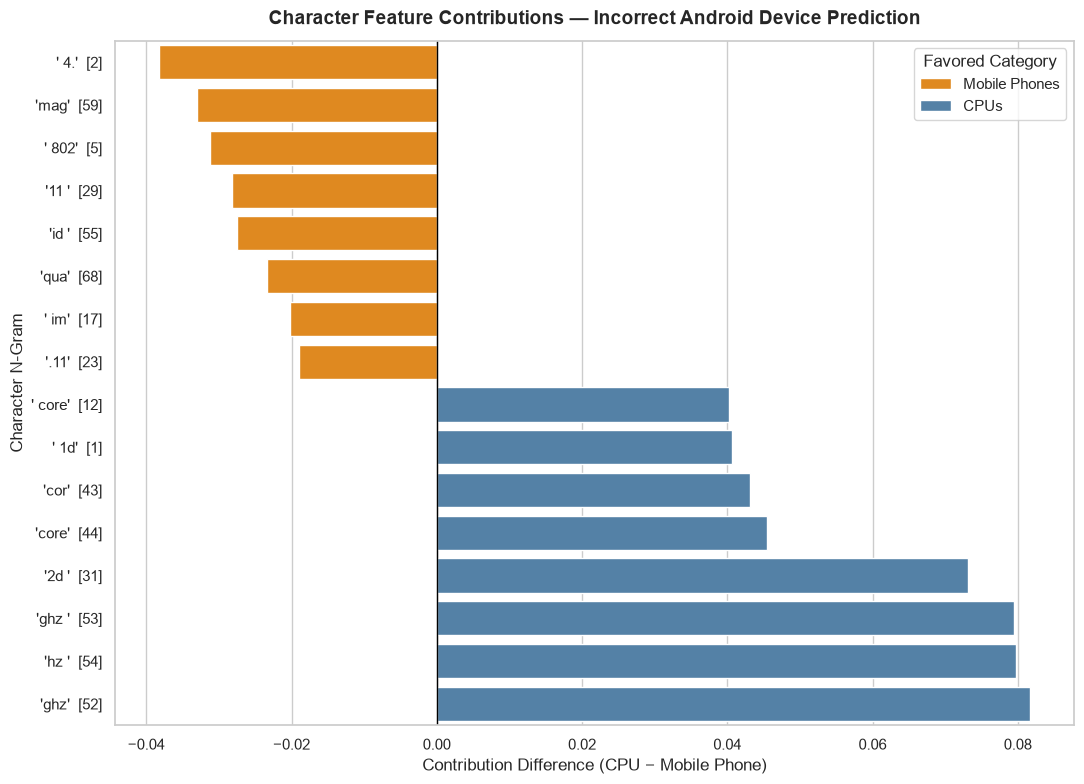

In [14]:
# Selecting the strongest features favoring each category
comparison_plot_df = pd.concat([
    top_cpu_features.head(8),
    top_mobile_features.head(8)
]).copy()

# Identifying the favored category
comparison_plot_df["Favored_Category"] = np.where(
    comparison_plot_df["CPU_Minus_Mobile"] > 0,
    "CPUs",
    "Mobile Phones"
)

# Sorting by contribution difference
comparison_plot_df = comparison_plot_df.sort_values(
    "CPU_Minus_Mobile"
)

# Creating unique feature labels
comparison_plot_df["Feature_Label"] = (
    comparison_plot_df["Character_Feature"]
    + "  [" + comparison_plot_df.index.astype(str) + "]"
)

# Creating the visualization
fig, ax = plt.subplots(figsize=(11, 8))

sns.barplot(
    data=comparison_plot_df,
    x="CPU_Minus_Mobile",
    y="Feature_Label",
    hue="Favored_Category",
    palette={
        "CPUs": "steelblue",
        "Mobile Phones": "darkorange"
    },
    dodge=False,
    ax=ax
)

ax.axvline(0, color="black", linewidth=1)

ax.set_title(
    "Character Feature Contributions — Incorrect Android Device Prediction",
    fontsize=14,
    fontweight="bold",
    pad=12
)

ax.set_xlabel("Contribution Difference (CPU − Mobile Phone)")
ax.set_ylabel("Character N-Gram")

ax.legend(title="Favored Category")

plt.tight_layout()
plt.show()

#### Analyzing Feature Contributions Across Correct Predictions

In [15]:
# Selecting one correctly classified sample per category
category_sample_records = []

for class_idx, category in enumerate(category_names):

    # Identifying correctly classified samples
    matching_indices = np.flatnonzero(
        (y_test == class_idx) &
        (y_test_pred == class_idx)
    )

    if len(matching_indices) == 0:
        continue

    # Selecting the first matching sample
    sample_idx = int(matching_indices[0])

    # Extracting active features
    sample_features = X_test_char.getrow(sample_idx)

    active_indices = sample_features.indices
    active_values = sample_features.data

    # Calculating feature contributions
    contributions = (
        active_values
        * model_coefficients[class_idx, active_indices]
    )

    # Identifying the strongest positive contributions
    top_indices = np.argsort(contributions)[-5:][::-1]

    top_features = [
        repr(feature_names[active_indices[idx]])
        for idx in top_indices
        if contributions[idx] > 0
    ]

    # Recording the sample explanation
    category_sample_records.append({
        "Category": category,
        "Product_Title": test_df.iloc[sample_idx]["Product_Title"],
        "Top_Positive_Features": ", ".join(top_features)
    })

# Creating the category explanation summary
category_explanations_df = pd.DataFrame(
    category_sample_records
)

print("Representative Correct Predictions by Category:")
display(category_explanations_df)

print("\nCategory-level local explanations generated successfully.")

Representative Correct Predictions by Category:


,Category,Product_Title,Top_Positive_Features
0,CPUs,intel core intel core i7 7700 processor 8m cache up to 4.20 ghz,"'ntel ', 'intel', 'ntel', 'ghz', 'i7 '"
1,Digital Cameras,canon powershot sx730 hs schwarz,"'sho', 'shot ', 'shot', 'hot ', 'ano'"
2,Dishwashers,bosch sms25ab00g serie 2 free standing dishwasher black,"' di', 'sms', 'dis', 'dish', ' dish'"
3,Freezers,blomberg fnt9673p tall freezer,"' fn', ' fr', 'fnt', ' fnt', 'ezer '"
4,Fridge Freezers,bosch kgn36vw35g fridge freezer,"' kg', 'kgn', 'kgn3', ' kgn', 'idge '"
5,Fridges,bosch kur15a50gb built in under larder fridge in white,"' ku', ' fr', 'der', 'der ', 'r15'"
6,Microwaves,bosch hmt72m450b silver freestanding microwave oven,"'hmt', ' hmt', ' hm', 'wav', 'wave '"
7,Mobile Phones,iphone 6s space grey 128gb 4.7 unlocked sim free,"'hon', 'one', 'gb ', 'one ', 'hone'"
8,TVs,sony kd49xf8096bu 49 4k hdr smart android tv with youview 400hz,"' tv', 'tv ', ' tv ', ' kd', ' 49'"
9,Washing Machines,bosch wiw28300gb serie 6 8kg 1400rpm integrated washing machine white,"' wa', ' was', 'kg ', ' wash', '283'"



Category-level local explanations generated successfully.


**Observations on Category-Level Local Explanations:**

- The model identified recognizable category-specific patterns such as `intel` and `ghz` for CPUs, `dish` for Dishwashers, and `wave` for Microwaves.
- Mobile Phones, TVs, and Washing Machines exhibited meaningful character sequences such as `hone`, `tv`, and `wash`, supporting their respective predictions.
- Several categories also relied on product model identifiers, demonstrating that the classifier combines descriptive terminology with learned product naming conventions.

#### Validating Local Feature Contribution Explanations

In [16]:
# Selecting representative samples for validation
validation_indices = [
    correct_sample_idx,
    incorrect_sample_idx
]

validation_records = []

for sample_idx in validation_indices:

    # Extracting the sample and predicted category
    sample_features = X_test_char.getrow(sample_idx)
    predicted_class = int(y_test_pred[sample_idx])

    # Calculating feature contributions
    feature_contributions = (
        sample_features.data
        * model_coefficients[
            predicted_class,
            sample_features.indices
        ]
    )

    # Reconstructing the decision score
    contribution_sum = feature_contributions.sum()

    intercept = final_model.intercept_[predicted_class]

    reconstructed_score = contribution_sum + intercept

    # Retrieving the original model decision score
    actual_score = final_model.decision_function(
        sample_features
    )[0, predicted_class]

    # Recording validation results
    validation_records.append({
        "Sample_Index": sample_idx,
        "Predicted_Category": category_names[predicted_class],
        "Feature_Contribution_Sum": contribution_sum,
        "Intercept": intercept,
        "Reconstructed_Score": reconstructed_score,
        "Model_Decision_Score": actual_score,
        "Absolute_Difference": abs(
            reconstructed_score - actual_score
        )
    })

# Creating validation summary
contribution_validation_df = pd.DataFrame(
    validation_records
)

print("Local Feature Contribution Validation:")
display(contribution_validation_df.round(6))

# Verifying numerical consistency
assert np.allclose(
    contribution_validation_df["Reconstructed_Score"],
    contribution_validation_df["Model_Decision_Score"]
)

print("\nLocal feature contributions validated successfully.")

Local Feature Contribution Validation:


,Sample_Index,Predicted_Category,Feature_Contribution_Sum,Intercept,Reconstructed_Score,Model_Decision_Score,Absolute_Difference
0,0,Mobile Phones,1.6401,-0.6336,1.0065,1.0065,0.0000
1,230,CPUs,0.5115,-0.8945,-0.3830,-0.3830,0.0000



Local feature contributions validated successfully.


**Observations on Local Feature Contribution Validation:**

- The reconstructed decision scores matched the original Ridge Classifier scores for both representative predictions.
- The correctly classified Mobile Phone example produced a reconstructed score of **1.0065**, while the incorrectly classified CPU prediction produced **-0.3830**.
- The validation confirms that the calculated feature contributions and intercepts accurately reproduce the model's decision scores, supporting the reliability of the local explanations.